In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from pathlib import Path

RAW_DIR = Path("data/raw")
PROCESSED_DIR = Path("data/processed")
RAW_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 12)
plt.rcParams["figure.figsize"] = (10, 4)

## Data Acquisition

In [2]:
UNIVERSE = {
    "CAD": {"fx_ticker": "USDCAD=X", "flip_fx_sign": True,
            "commodity_ticker": "CL=F", "commodity_name": "WTI Crude Oil"},
    "NOK": {"fx_ticker": "USDNOK=X", "flip_fx_sign": True,
            "commodity_ticker": "BZ=F", "commodity_name": "Brent Crude Oil"},
    "AUD": {"fx_ticker": "AUDUSD=X", "flip_fx_sign": False,
            "commodity_ticker": "HG=F", "commodity_name": "Copper"},
}
DOLLAR_INDEX_TICKER = "UUP"  # Invesco DB USD Index Bullish Fund ETF, a liquid tradable USD-strength proxy

# Filenames deliberately kept human-readable rather than derived mechanically from the ticker string.
FILENAME_MAP = {
    "USDCAD=X": "USDCAD", "USDNOK=X": "USDNOK", "AUDUSD=X": "AUDUSD",
    "CL=F": "WTI", "BZ=F": "BRENT", "HG=F": "COPPER", "UUP": "USD",
}

START_DATE = "2010-01-01"

In [3]:
STALE_AFTER_DAYS = 5  # refresh a cached snapshot if its last observation is older than this many calendar days
USE_SNAPSHOT = True   # always load the submitted snapshot when present, so a re-run reproduces the reported results

def download_or_load_raw(ticker: str, start: str = START_DATE) -> pd.DataFrame:
    path = RAW_DIR / f"{FILENAME_MAP[ticker]}.csv"
    if path.exists():
        if USE_SNAPSHOT:
            return pd.read_csv(path)
        raw = pd.read_csv(path, skiprows=[1, 2])
        last_date = pd.to_datetime(raw.iloc[:, 0]).max()
        if (pd.Timestamp.today() - last_date).days <= STALE_AFTER_DAYS:
            return pd.read_csv(path)
        print(f"  {ticker}: cached snapshot stale (last date {last_date.date()}), refreshing...")
    df = yf.download(ticker, start=start, auto_adjust=True, progress=False)
    df.to_csv(path)
    return pd.read_csv(path)

all_tickers = ([DOLLAR_INDEX_TICKER]
               + [v["fx_ticker"] for v in UNIVERSE.values()]
               + [v["commodity_ticker"] for v in UNIVERSE.values()])

for ticker in all_tickers:
    rows = len(download_or_load_raw(ticker))
    print(f"{ticker:10s} -> {FILENAME_MAP[ticker]}.csv, {rows} rows")

UUP        -> USD.csv, 4200 rows
USDCAD=X   -> USDCAD.csv, 4347 rows
USDNOK=X   -> USDNOK.csv, 4349 rows
AUDUSD=X   -> AUDUSD.csv, 4348 rows
CL=F       -> WTI.csv, 4201 rows
BZ=F       -> BRENT.csv, 4170 rows
HG=F       -> COPPER.csv, 4201 rows


In [4]:
def parse_raw_price_csv(ticker: str) -> pd.Series:
    path = RAW_DIR / f"{FILENAME_MAP[ticker]}.csv"
    raw = pd.read_csv(path, skiprows=[1, 2])
    raw = raw.rename(columns={raw.columns[0]: "Date"})
    close = raw.set_index("Date")["Close"]
    close.index = pd.to_datetime(close.index)
    close.name = ticker
    return close.sort_index()

prices = pd.DataFrame({ticker: parse_raw_price_csv(ticker) for ticker in all_tickers})

for col in prices.columns:
    s = prices[col].dropna()
    print(f"  {col:10s} {s.index.min().date()} -> {s.index.max().date()}  ({len(s)} obs)")

  UUP        2010-01-04 -> 2026-09-11  (4198 obs)
  USDCAD=X   2010-01-01 -> 2026-09-11  (4345 obs)
  USDNOK=X   2010-01-01 -> 2026-09-14  (4347 obs)
  AUDUSD=X   2010-01-01 -> 2026-09-14  (4346 obs)
  CL=F       2010-01-04 -> 2026-09-14  (4199 obs)
  BZ=F       2010-01-04 -> 2026-09-14  (4168 obs)
  HG=F       2010-01-04 -> 2026-09-14  (4199 obs)


## Data Cleaning and Alignment

Identifying days where at least one commodity future is being traded

In [5]:
commodity_tickers = [v["commodity_ticker"] for v in UNIVERSE.values()]
calendar = prices[commodity_tickers].dropna(how="all").index
aligned = prices.reindex(calendar)

print("Missing observations after reindexing onto the commodity calendar:")
print(aligned.isna().sum())

Missing observations after reindexing onto the commodity calendar:
UUP          4
USDCAD=X     8
USDNOK=X     6
AUDUSD=X     7
CL=F         1
BZ=F        32
HG=F         1
dtype: int64


Forward fill with the last known price for at most 2 days. This avoids blanks when building signals. It is an acceptable compromise because there is no look ahead, nor does it largely affect the signal largely. 

In [6]:
FFILL_LIMIT = 2
aligned = aligned.ffill(limit=FFILL_LIMIT)

print(f"Missing observations after bounded forward-fill (limit={FFILL_LIMIT} days):")
print(aligned.isna().sum())

rows_before = len(aligned)
aligned = aligned.dropna()
print(f"\nDropped {rows_before - len(aligned)} rows ({(rows_before - len(aligned)) / rows_before:.2%}) that still had "
      f"a missing value after fill; {len(aligned)} rows remain, "
      f"spanning {aligned.index.min().date()} to {aligned.index.max().date()}.")

Missing observations after bounded forward-fill (limit=2 days):
UUP         0
USDCAD=X    0
USDNOK=X    0
AUDUSD=X    0
CL=F        0
BZ=F        0
HG=F        0
dtype: int64

Dropped 0 rows (0.00%) that still had a missing value after fill; 4200 rows remain, spanning 2010-01-04 to 2026-09-14.


Gatekeeping for bad ticks (discovered retrospectively) and replacing with 3-day median. Example cases:
- The close was below the low of the day
- There were major 30% drops that were reversed the next day

Flagging strategy: if the day's closing price is more than 5% away from the median of the previous, current and next day's closing prices, then it is flagged. It is replaced with the median of the three day period

In [7]:
def detect_and_despike(prices: pd.DataFrame, columns: list[str], window: int = 3, threshold: float = 0.05):
    cleaned = prices.copy()
    flagged = []
    for col in columns:
        s = prices[col]
        rolling_median = s.rolling(window, center=True, min_periods=window).median()
        deviation = (s - rolling_median).abs() / rolling_median
        is_spike = deviation > threshold
        for date in s.index[is_spike]:
            flagged.append((col, date.date(), s.loc[date], rolling_median.loc[date]))
        cleaned[col] = s.mask(is_spike, rolling_median)
    return cleaned, flagged

FX_AND_DOLLAR_COLS = [DOLLAR_INDEX_TICKER] + [v["fx_ticker"] for v in UNIVERSE.values()]
aligned, despike_log = detect_and_despike(aligned, FX_AND_DOLLAR_COLS, threshold=0.05)

print(f"Despiked {len(despike_log)} isolated bad tick(s):")
for col, date, bad_value, replacement in despike_log:
    print(f"  {col} on {date}: {bad_value:.5f} -> {replacement:.5f} (3-day local median)")

aligned.to_csv(PROCESSED_DIR / "aligned_prices.csv")

Despiked 2 isolated bad tick(s):
  USDNOK=X on 2020-03-20: 7.73532 -> 10.77912 (3-day local median)
  USDNOK=X on 2021-12-27: 7.99910 -> 8.82972 (3-day local median)


Masking for negative WTI price during covid to avoid including in log returns. We do not forward fill in this case, as we are not filling 'missing prices' as with previous forward fills. 

In [8]:
non_positive = (aligned <= 0)
if non_positive.any().any():
    for col in aligned.columns[non_positive.any()]:
        dates = aligned.index[non_positive[col]]
        print(f"Non-positive price(s) in {col}: {[d.date() for d in dates]} -> value(s) {aligned.loc[dates, col].tolist()}")

# Mask non-positive prices to NaN *before* taking logs, so the one affected log return is an explicit,
# documented missing value rather than a silent RuntimeWarning from log() of a negative number.
prices_for_log = aligned.where(aligned > 0)
log_returns = np.log(prices_for_log / prices_for_log.shift(1))

masked_return_dates = log_returns.index[1:][log_returns["CL=F"].iloc[1:].isna()]
print(f"CL=F log returns left missing by the mask: {[d.date() for d in masked_return_dates]}")

Non-positive price(s) in CL=F: [datetime.date(2020, 4, 20)] -> value(s) [-37.630001068115234]
CL=F log returns left missing by the mask: [datetime.date(2020, 4, 20), datetime.date(2020, 4, 21)]


Construction of 3 tables
- commodity_returns: raw daily log returns of oil and copper, used in future for deciding position
- domestic_fx_returns: used to determine P&L by multiplying by position
- dollar_index_return: used to strip the dollar effect 

In [9]:
domestic_fx_returns = pd.DataFrame(index=log_returns.index)
commodity_returns = pd.DataFrame(index=log_returns.index)

for ccy, spec in UNIVERSE.items():
    fx_ret = log_returns[spec["fx_ticker"]]
    if spec["flip_fx_sign"]:
        fx_ret = -fx_ret
    domestic_fx_returns[ccy] = fx_ret
    commodity_returns[ccy] = log_returns[spec["commodity_ticker"]]

dollar_index_return = log_returns[DOLLAR_INDEX_TICKER]

# dollar_index_return.head()
# domestic_fx_returns.head()
# commodity_returns.head()

function that sums trailing return

It is always used as `trailing_return(...).shift(1)`. The one-day shift means the value used on day t only includes data up to day t−1, so a decision never uses that day's own prices (this avoids look-ahead bias).

In [10]:
def trailing_return(returns: pd.Series, window: int) -> pd.Series:
    """Cumulative log return over the trailing `window` days ending on day t inclusive (before any lag is applied)."""
    return returns.rolling(window).sum()

## Exploratory Analysis

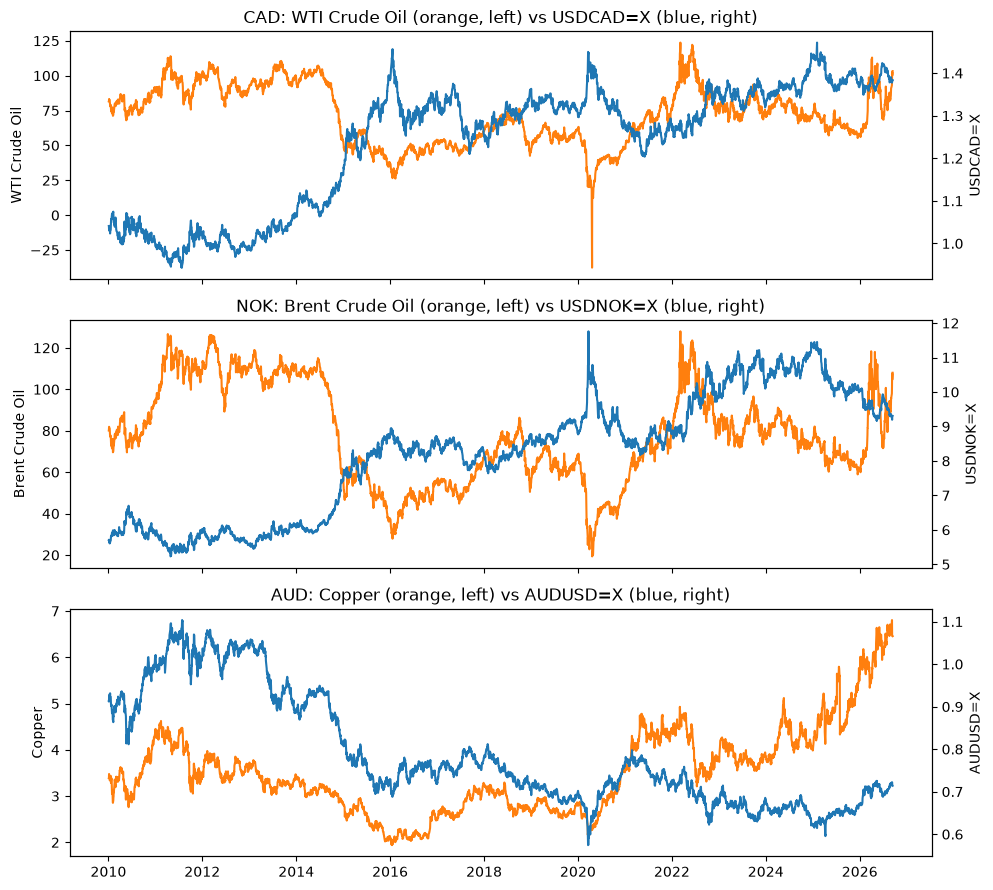

In [11]:
fig, axes = plt.subplots(len(UNIVERSE), 1, figsize=(10, 3 * len(UNIVERSE)), sharex=True)
for ax, (ccy, spec) in zip(axes, UNIVERSE.items()):
    ax2 = ax.twinx()
    ax.plot(aligned.index, aligned[spec["commodity_ticker"]], color="tab:orange")
    ax2.plot(aligned.index, aligned[spec["fx_ticker"]], color="tab:blue")
    ax.set_title(f"{ccy}: {spec['commodity_name']} (orange, left) vs {spec['fx_ticker']} (blue, right)")
    ax.set_ylabel(spec["commodity_name"])
    ax2.set_ylabel(spec["fx_ticker"])
fig.tight_layout()
plt.show()

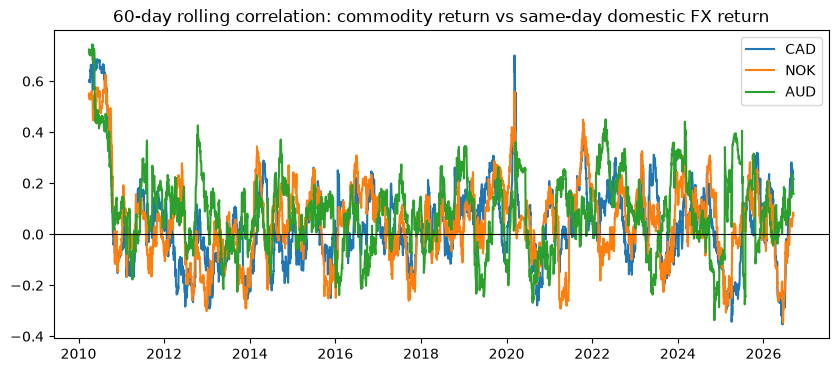

In [12]:
fig, ax = plt.subplots()
for ccy in UNIVERSE:
    ax.plot(commodity_returns.index, commodity_returns[ccy].rolling(60).corr(domestic_fx_returns[ccy]), label=ccy)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("60-day rolling correlation: commodity return vs same-day domestic FX return")
ax.legend()
plt.show()

The correlation starts near 0.6-0.7 in 2010 and then collapses to roughly ±0.2 from
late 2010 onward. That drop is not a change in the economics; it is a data-timestamp effect. Yahoo's daily FX bars and the US-listed futures and ETF series turn out to be offset by about one trading day from late 2010.

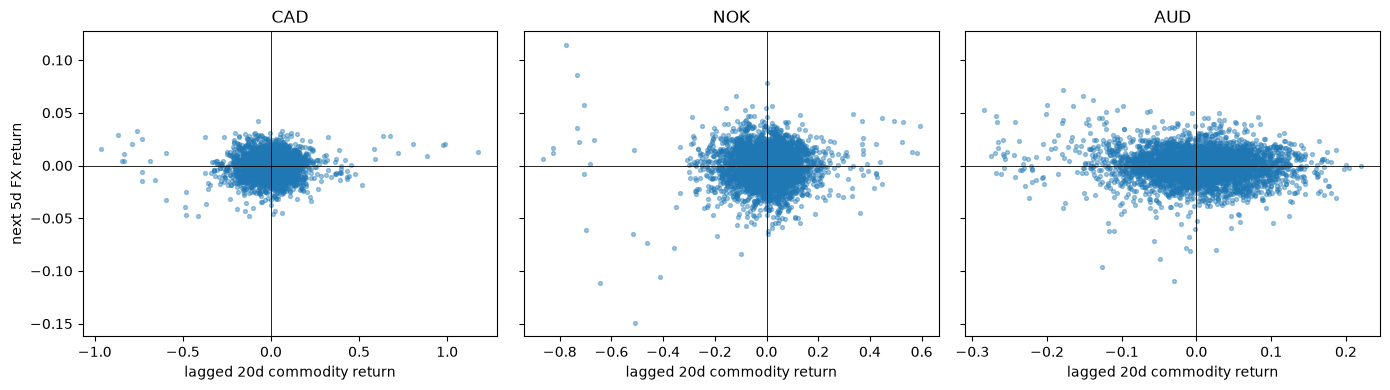

In [13]:
fig, axes = plt.subplots(1, len(UNIVERSE), figsize=(14, 4), sharey=True)
for ax, ccy in zip(axes, UNIVERSE):
    lagged_commodity_20d = trailing_return(commodity_returns[ccy], 20).shift(1)
    forward_fx_5d = domestic_fx_returns[ccy].shift(-5).rolling(5).sum()
    ax.scatter(lagged_commodity_20d, forward_fx_5d, s=8, alpha=0.4)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.axvline(0, color="black", linewidth=0.6)
    ax.set_title(ccy)
    ax.set_xlabel("lagged 20d commodity return")
axes[0].set_ylabel("next 5d FX return")
fig.tight_layout()
plt.show()

Scatter of each currency's lagged 20-day commodity return against its *next* 5-day FX return, for a visual sanity test of any correlation

## Signal Construction

In [14]:
STANDARDISATION_WINDOW = 252      # ~1 trading year, used to z-score the trailing commodity return
LOOKBACK_GRID = [10, 20, 40]      # trailing commodity-return window, in trading days
THRESHOLD_GRID = [0.0, 0.5, 1.0]  # z-score cutoff for entering a position
POSITION_WEIGHT = 1 / 3           # fixed weight per currency when a position is active; no renormalisation

IN_SAMPLE_END = "2018-12-31"
OOS_START = "2019-01-01"

# One-way transaction cost assumption per rebalance, in basis points of notional. CAD and AUD spot are
# among the most liquid pairs traded; NOK is a G10 pair but visibly thinner, so it is assigned a higher
# base-case cost.
BASE_COST_BPS = {"CAD": 2.0, "AUD": 2.0, "NOK": 5.0}


def zscore_signal(returns: pd.Series, lookback: int, standardisation_window: int = STANDARDISATION_WINDOW) -> pd.Series:
    """Rolling z-score of the one-day-lagged trailing `lookback`-day return."""
    raw_lagged = trailing_return(returns, lookback).shift(1)
    return (raw_lagged - raw_lagged.rolling(standardisation_window).mean()) / raw_lagged.rolling(standardisation_window).std()


def positions_from_zscore(z: pd.Series, threshold: float) -> pd.Series:
    """+1 long / -1 short / 0 flat, by z-score against a symmetric threshold."""
    pos = pd.Series(np.where(z > threshold, 1.0, np.where(z < -threshold, -1.0, 0.0)), index=z.index)
    pos[z.isna()] = np.nan
    return pos

In [15]:
def weekly_backtest(ccy: str, position_daily: pd.Series, cost_bps: float, cost_multiplier: float = 1.0) -> pd.DataFrame:
    weekly_position = position_daily.resample("W-FRI").last()
    weekly_position_active = weekly_position.shift(1)  # decided at end of week W, held during week W+1
    weekly_fx_return = domestic_fx_returns[ccy].resample("W-FRI").sum()

    gross_return = weekly_position_active * weekly_fx_return * POSITION_WEIGHT
    turnover = weekly_position_active.diff().abs().fillna(0.0)
    cost = turnover * POSITION_WEIGHT * (cost_bps * cost_multiplier / 1e4)

    return pd.DataFrame({
        "position": weekly_position_active, "gross_return": gross_return,
        "turnover": turnover, "cost": cost, "net_return": gross_return - cost,
    })


def run_strategy(lookback: int, threshold: float, cost_multiplier: float = 1.0,
                 signal_source: dict = None, cost_bps_map: dict = None):
    """Run the per-currency z-score strategy; returns (per-currency frames, portfolio net return, portfolio turnover).

    `signal_source` defaults to `commodity_returns` (the hypothesis's actual signal); passing `domestic_fx_returns`
    instead gives the naive FX-self-momentum benchmark built in the Benchmarks section, reusing the same machinery.
    """
    signal_source = commodity_returns if signal_source is None else signal_source
    cost_bps_map = BASE_COST_BPS if cost_bps_map is None else cost_bps_map
    per_ccy = {}
    for ccy in UNIVERSE:
        z = zscore_signal(signal_source[ccy], lookback)
        pos = positions_from_zscore(z, threshold)
        per_ccy[ccy] = weekly_backtest(ccy, pos, cost_bps_map[ccy], cost_multiplier)
    portfolio_net = pd.concat({c: f["net_return"] for c, f in per_ccy.items()}, axis=1).sum(axis=1, min_count=1)
    portfolio_turnover = pd.concat({c: f["turnover"] for c, f in per_ccy.items()}, axis=1).sum(axis=1, min_count=1)
    return per_ccy, portfolio_net, portfolio_turnover

## Backtest and Results

Run the strategy based on different configurations, then we look at who performs the best

In [16]:
def performance_metrics(weekly_returns: pd.Series, periods_per_year: int = 52) -> pd.Series:
    r = weekly_returns.dropna()
    cumulative_return = (1 + r).prod() - 1
    n_years = len(r) / periods_per_year
    annualised_return = (1 + cumulative_return) ** (1 / n_years) - 1 if n_years > 0 else np.nan
    annualised_vol = r.std() * np.sqrt(periods_per_year)
    equity_curve = (1 + r).cumprod()
    return pd.Series({
        "cumulative_return": cumulative_return,
        "annualised_return": annualised_return,
        "annualised_vol": annualised_vol,
        "sharpe": annualised_return / annualised_vol if annualised_vol > 0 else np.nan,
        "max_drawdown": (equity_curve / equity_curve.cummax() - 1).min(),
        "hit_rate": (r > 0).mean(),
        "n_weeks": len(r),
    })

In [17]:
import time

grid_results = {}
start = time.perf_counter()
for lookback in LOOKBACK_GRID:
    for threshold in THRESHOLD_GRID:
        per_ccy, portfolio_net, portfolio_turnover = run_strategy(lookback, threshold)
        grid_results[(lookback, threshold)] = {
            "per_ccy": per_ccy, "net": portfolio_net, "turnover": portfolio_turnover,
        }
GRID_SEARCH_SECONDS = time.perf_counter() - start

grid_rows = []
for (lookback, threshold), res in grid_results.items():
    ins = performance_metrics(res["net"][:IN_SAMPLE_END])
    oos = performance_metrics(res["net"][OOS_START:])
    grid_rows.append({
        "lookback": lookback, "threshold": threshold,
        "is_sharpe": ins["sharpe"], "is_cum_return": ins["cumulative_return"],
        "oos_sharpe": oos["sharpe"], "oos_cum_return": oos["cumulative_return"],
    })

grid_df = pd.DataFrame(grid_rows).sort_values("is_sharpe", ascending=False).reset_index(drop=True)

print(f"{len(grid_results)} configurations evaluated in {GRID_SEARCH_SECONDS:.3f}s\n")
print("In-sample ranking (the only columns consulted to select a configuration):")
grid_df[["lookback", "threshold", "is_sharpe", "is_cum_return"]]

9 configurations evaluated in 0.162s

In-sample ranking (the only columns consulted to select a configuration):


,lookback,threshold,is_sharpe,is_cum_return
0,40,1.0,0.381350,0.137713
1,40,0.0,0.370357,0.219961
2,40,0.5,0.354765,0.177973
3,10,1.0,-0.022000,-0.006193
4,20,1.0,-0.312690,-0.094651
5,20,0.0,-0.366473,-0.172056
6,20,0.5,-0.470691,-0.180033
7,10,0.5,-0.494362,-0.170171
8,10,0.0,-0.552118,-0.241536


Looking at the best performing configuration based on sharpe ratio, while also setting this configuration as the best choice

In [18]:
BEST_LOOKBACK = int(grid_df.iloc[0]["lookback"])
BEST_THRESHOLD = float(grid_df.iloc[0]["threshold"])
print(f"Selected in-sample: lookback={BEST_LOOKBACK}d, threshold={BEST_THRESHOLD} "
      f"(out of {len(grid_df)} variations tried, chosen by in-sample net Sharpe)")

# Retrieved from the stored grid -- the winning configuration is not re-run.
best = grid_results[(BEST_LOOKBACK, BEST_THRESHOLD)]
per_ccy, portfolio_net, portfolio_turnover = best["per_ccy"], best["net"], best["turnover"]

in_sample_returns = portfolio_net[:IN_SAMPLE_END]
oos_returns = portfolio_net[OOS_START:]

results_table = pd.DataFrame({
    "in_sample": performance_metrics(in_sample_returns),
    "out_of_sample": performance_metrics(oos_returns),
})
results_table

Selected in-sample: lookback=40d, threshold=1.0 (out of 9 variations tried, chosen by in-sample net Sharpe)


,in_sample,out_of_sample
cumulative_return,0.137713,-0.078743
annualised_return,0.016580,-0.010527
annualised_vol,0.043476,0.053444
sharpe,0.381350,-0.196969
max_drawdown,-0.093085,-0.200890
hit_rate,0.377451,0.302730
n_weeks,408.000000,403.000000


Getting the 'real' hit rate, accounting only for weeks where we actually have a position active.

In [19]:
# Hit rate restricted to weeks in which at least one currency had an open position (see the metrics note above).
invested = pd.DataFrame({ccy: per_ccy[ccy]["position"] for ccy in UNIVERSE}).abs().sum(axis=1) > 0
for label, r in [("in-sample", in_sample_returns), ("out-of-sample", oos_returns)]:
    r = r.dropna()
    has_position = invested.reindex(r.index, fill_value=False)
    print(f"{label:14s}: fully flat in {1 - has_position.mean():.1%} of weeks; hit rate {(r > 0).mean():.1%} over all "
          f"weeks, {(r[has_position] > 0).mean():.1%} over weeks with a position open")

in-sample     : fully flat in 34.1% of weeks; hit rate 37.7% over all weeks, 57.2% over weeks with a position open
out-of-sample : fully flat in 41.7% of weeks; hit rate 30.3% over all weeks, 51.9% over weeks with a position open


t-testing, for significance of returns (null hypothesis - 0, a two tailed test)

In [20]:
def mean_return_tstat(weekly_returns: pd.Series) -> float:
    """t-statistic of the mean weekly return against zero, treating weeks as independent."""
    r = weekly_returns.dropna()
    return r.mean() / (r.std() / np.sqrt(len(r)))


is_r, oos_r = in_sample_returns.dropna(), oos_returns.dropna()
significance_table = pd.DataFrame({
    label: {"mean_weekly_return_bps": r.mean() * 1e4, "arithmetic_sharpe": r.mean() / r.std() * np.sqrt(52),
            "t_stat": mean_return_tstat(r), "n_weeks": len(r)}
    for label, r in [("in_sample", is_r), ("out_of_sample", oos_r)]
})
difference_t = (is_r.mean() - oos_r.mean()) / np.sqrt(is_r.var() / len(is_r) + oos_r.var() / len(oos_r))
print(f"t-statistic of the in-sample minus out-of-sample difference in mean weekly return: {difference_t:.2f}")
significance_table.round(3)

t-statistic of the in-sample minus out-of-sample difference in mean weekly return: 1.08


,in_sample,out_of_sample
mean_weekly_return_bps,3.344,-1.764
arithmetic_sharpe,0.400,-0.172
t_stat,1.120,-0.478
n_weeks,408.000,403.000


**Result: neither period is statistically distinguishable from zero.** 

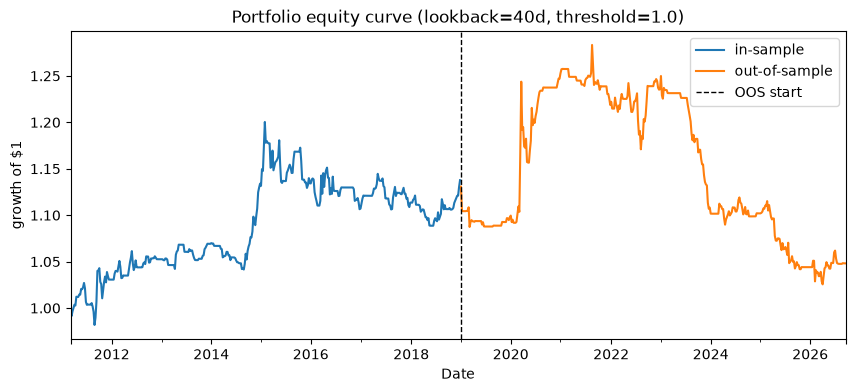

In [21]:
fig, ax = plt.subplots()
is_equity = (1 + in_sample_returns.dropna()).cumprod()
is_equity.plot(ax=ax, label="in-sample")
((1 + oos_returns.dropna()).cumprod() * is_equity.iloc[-1]).plot(ax=ax, label="out-of-sample")
ax.axvline(pd.Timestamp(OOS_START), color="black", linestyle="--", linewidth=1, label="OOS start")
ax.set_title(f"Portfolio equity curve (lookback={BEST_LOOKBACK}d, threshold={BEST_THRESHOLD})")
ax.set_ylabel("growth of $1")
ax.legend()
plt.show()

In [22]:
contributions = pd.DataFrame({ccy: per_ccy[ccy]["net_return"] for ccy in UNIVERSE})
contributions["portfolio"] = portfolio_net
yearly_pnl = contributions.groupby(contributions.index.year).sum().loc[2011:]
yearly_pnl.index.name = "year"
display(yearly_pnl.round(4))

for label, period in [("in-sample", slice(None, IN_SAMPLE_END)), ("out-of-sample", slice(OOS_START, None))]:
    print(f"{label:14s} by currency: "
          + ", ".join(f"{ccy} {contributions[ccy][period].sum():+.1%}" for ccy in UNIVERSE))

oil_crash_share = in_sample_returns["2014-07-01":"2015-06-30"].sum() / in_sample_returns.sum()
print(f"\nShare of in-sample net P&L earned July 2014 - June 2015 (the oil crash): {oil_crash_share:.0%}")
oos_2020 = oos_returns.loc["2020"].sum()
oos_other_years = oos_returns[oos_returns.index.year != 2020].sum()
print(f"Out-of-sample net P&L in 2020: {oos_2020:+.1%}; all other out-of-sample years combined: {oos_other_years:+.1%}")

,CAD,NOK,AUD,portfolio
year,,,,
2011,0.0198,0.0046,0.0072,0.0317
2012,-0.0018,0.0280,-0.0047,0.0215
2013,-0.0046,0.0157,0.0048,0.0159
2014,0.0164,0.0534,-0.0104,0.0594
2015,0.0083,-0.0348,0.0292,0.0026
2016,0.0040,-0.0082,-0.0185,-0.0228
2017,0.0012,-0.0021,0.0072,0.0063
2018,0.0072,0.0150,-0.0003,0.0219
2019,-0.0163,-0.0168,-0.0024,-0.0354


in-sample      by currency: CAD +5.0%, NOK +7.2%, AUD +1.4%
out-of-sample  by currency: CAD -2.4%, NOK -3.8%, AUD -0.9%

Share of in-sample net P&L earned July 2014 - June 2015 (the oil crash): 57%
Out-of-sample net P&L in 2020: +13.3%; all other out-of-sample years combined: -20.5%


In-sample: more than half of the profit came from one 12-month window, the 2014-15 oil crash.

Out-of-sample: 2020 (the COVID shock) was strongly positive and the remaining years combined lost about 20%. 

All three currencies made money in-sample and all three lost out-of-sample, so the result is not driven by one currency; but in both periods it is driven by one or two macro episodes rather than by a steady weekly drift. 

The strategy earns positive Sharpe in-sample and a negative sharpe out of sample, but neither distinguishable from zero, and are dominated by maco episodes.

## Benchmarks and Transaction Cost Sensitivity

Ruling out two possible explanations for the out of sample failure and failed t-test:
1.  *Any* FX exposure would have lost money over this period
  - Buy-and-hold, long on all three currencies at 1/3 for each
  - Trading currency on its own past return rather than commodity's momentum (using the same parameters)
2. Transaction costs negated the winnings

In [23]:
buy_and_hold_frames = {
    ccy: weekly_backtest(ccy, pd.Series(1.0, index=domestic_fx_returns.index), BASE_COST_BPS[ccy])
    for ccy in UNIVERSE
}
buy_and_hold_net = pd.concat({c: f["net_return"] for c, f in buy_and_hold_frames.items()}, axis=1).sum(axis=1, min_count=1)

_, fx_momentum_net, _ = run_strategy(BEST_LOOKBACK, BEST_THRESHOLD, signal_source=domestic_fx_returns)

benchmark_table = pd.DataFrame({
    "strategy": performance_metrics(oos_returns),
    "buy_and_hold_fx": performance_metrics(buy_and_hold_net[OOS_START:]),
    "naive_fx_momentum": performance_metrics(fx_momentum_net[OOS_START:]),
})
benchmark_table

,strategy,buy_and_hold_fx,naive_fx_momentum
cumulative_return,-0.078743,-0.049417,-0.097940
annualised_return,-0.010527,-0.006518,-0.013212
annualised_vol,0.053444,0.088337,0.054868
sharpe,-0.196969,-0.073785,-0.240792
max_drawdown,-0.200890,-0.225398,-0.187040
hit_rate,0.302730,0.493797,0.250620
n_weeks,403.000000,403.000000,403.000000


Both benchmarks also lost money out-of-sample. The signal developed also barely beat the fx_momentum strategy, while performing worse than buy and hold.

We ompare sharpe ratio rather than cumulative return or drawdown due to the fact that buy and hold is fully invested all the time, while the strategy and naive_fx have period of being flat. 

In [24]:
cost_scenarios = {"gross (0x)": 0.0, "low (0.5x)": 0.5, "base (1x)": 1.0, "high (3x)": 3.0}
sensitivity = {}
for label, multiplier in cost_scenarios.items():
    _, net_returns, _ = run_strategy(BEST_LOOKBACK, BEST_THRESHOLD, cost_multiplier=multiplier)
    sensitivity[label] = performance_metrics(net_returns[OOS_START:])

pd.DataFrame(sensitivity)

,gross (0x),low (0.5x),base (1x),high (3x)
cumulative_return,-0.055942,-0.067412,-0.078743,-0.122718
annualised_return,-0.007401,-0.008965,-0.010527,-0.016752
annualised_vol,0.053421,0.053431,0.053444,0.053518
sharpe,-0.138535,-0.167783,-0.196969,-0.313012
max_drawdown,-0.186191,-0.193574,-0.200890,-0.229508
hit_rate,0.307692,0.302730,0.302730,0.295285
n_weeks,403.000000,403.000000,403.000000,403.000000


Even trading completely free, the strategy developed loses money.

## Why the Strategy Failed: Risk and Attribution

In [25]:
position_matrix = pd.DataFrame({ccy: per_ccy[ccy]["position"] for ccy in UNIVERSE}).dropna(how="all")
print("Correlation between the three currencies' weekly positions:")
print(position_matrix.corr().round(2))

same_direction_weeks = ((position_matrix > 0).sum(axis=1) >= 2) | ((position_matrix < 0).sum(axis=1) >= 2)
print(f"\nWeeks with 2+ currencies positioned in the same direction: {same_direction_weeks.mean():.1%}")

Correlation between the three currencies' weekly positions:
      CAD   NOK   AUD
CAD  1.00  0.82  0.27
NOK  0.82  1.00  0.30
AUD  0.27  0.30  1.00

Weeks with 2+ currencies positioned in the same direction: 32.3%


There is less diversification than originally proposed, since CAD and NOK will get largely the same signal

In [26]:
oos_equity = (1 + oos_returns.dropna()).cumprod()
drawdown = oos_equity / oos_equity.cummax() - 1
trough = drawdown.idxmin()
peak = oos_equity[:trough].idxmax()
print(f"Out-of-sample max drawdown: {drawdown.min():.1%}, underwater from {peak.date()} to {trough.date()}")

window_fx_return = {ccy: domestic_fx_returns[ccy][peak:trough].sum() for ccy in UNIVERSE}
print("Cumulative FX return over that window, by currency: "
      + ", ".join(f"{ccy} {r:+.1%}" for ccy, r in window_fx_return.items())
      + f" (average {np.mean(list(window_fx_return.values())):+.1%})")
print(f"Cumulative dollar-index (UUP) return over the same window: {dollar_index_return[peak:trough].sum():+.1%}")

# What the strategy actually held during the drawdown, and whether longs or shorts lost the money.
attribution = {}
for ccy in UNIVERSE:
    f = per_ccy[ccy][peak:trough]
    attribution[ccy] = {
        "long_weeks": (f["position"] > 0).sum(), "short_weeks": (f["position"] < 0).sum(),
        "flat_weeks": (f["position"] == 0).sum(), "avg_position": f["position"].mean(),
        "pnl_from_longs": f.loc[f["position"] > 0, "gross_return"].sum(),
        "pnl_from_shorts": f.loc[f["position"] < 0, "gross_return"].sum(),
        "costs": -f["cost"].sum(), "net_pnl": f["net_return"].sum(),
    }
window_frames = pd.concat([per_ccy[ccy][peak:trough] for ccy in UNIVERSE])
active_weeks = window_frames[window_frames["position"].abs() > 0]
print(f"Active currency-weeks in the window: {len(active_weeks)}, of which "
      f"{(active_weeks['gross_return'] > 0).mean():.1%} made money")
pd.DataFrame(attribution).T.astype({"long_weeks": int, "short_weeks": int, "flat_weeks": int}).round(4)

Out-of-sample max drawdown: -20.1%, underwater from 2021-08-20 to 2026-04-03
Cumulative FX return over that window, by currency: CAD -9.1%, NOK -8.6%, AUD -4.3% (average -7.4%)
Cumulative dollar-index (UUP) return over the same window: +25.1%
Active currency-weeks in the window: 276, of which 42.4% made money


,long_weeks,short_weeks,flat_weeks,avg_position,pnl_from_longs,pnl_from_shorts,costs,net_pnl
CAD,44,45,153,-0.0041,-0.0222,-0.0057,-0.0037,-0.0316
NOK,45,47,150,-0.0083,-0.0215,-0.0712,-0.0098,-0.1025
AUD,43,52,147,-0.0372,-0.0173,-0.0400,-0.0048,-0.0621


The positions lost on both long and shorts, meaning that it wasn't because of the dollar rally that dragged down the strategy. It was a genuine signal failure. 

In [27]:
DOLLAR_BETA_WINDOW = 252


def dollar_adjusted(returns: pd.Series, dollar: pd.Series, window: int = DOLLAR_BETA_WINDOW) -> pd.Series:
    """Residual of `returns` after removing the broad-USD component, using a slope estimated only on past data.

    min_periods lets the slope survive the two masked WTI returns (see Data Cleaning and Alignment) instead of going undefined for a year.
    """
    beta = (returns.rolling(window, min_periods=window // 2).cov(dollar)
            / dollar.rolling(window, min_periods=window // 2).var())
    return returns - beta.shift(1) * dollar


dollar_adjusted_commodity_returns = pd.DataFrame(
    {ccy: dollar_adjusted(commodity_returns[ccy], dollar_index_return) for ccy in UNIVERSE})

_, dollar_adjusted_net, _ = run_strategy(BEST_LOOKBACK, BEST_THRESHOLD, signal_source=dollar_adjusted_commodity_returns)
common_weeks = portfolio_net.dropna().index.intersection(dollar_adjusted_net.dropna().index)

adjusted_grid_oos_sharpe = [
    performance_metrics(run_strategy(lb, th, signal_source=dollar_adjusted_commodity_returns)[1][OOS_START:])["sharpe"]
    for lb in LOOKBACK_GRID for th in THRESHOLD_GRID
]
print(f"Frozen config (lookback={BEST_LOOKBACK}d, threshold={BEST_THRESHOLD}), compared over {len(common_weeks)} common "
      f"weeks from {common_weeks.min().date()}.")
print(f"Full 9-point grid on the dollar-adjusted signal: {sum(s > 0 for s in adjusted_grid_oos_sharpe)} of "
      f"{len(adjusted_grid_oos_sharpe)} configurations have a positive out-of-sample Sharpe.")

metric_rows = ["cumulative_return", "sharpe", "max_drawdown"]
dollar_test = {}
for label, series in [("raw signal", portfolio_net), ("dollar-adjusted signal", dollar_adjusted_net)]:
    s = series.loc[common_weeks]
    dollar_test[(label, "in_sample")] = performance_metrics(s[:IN_SAMPLE_END])[metric_rows]
    dollar_test[(label, "out_of_sample")] = performance_metrics(s[OOS_START:])[metric_rows]
pd.DataFrame(dollar_test).round(3)

Frozen config (lookback=40d, threshold=1.0), compared over 785 common weeks from 2011-09-09.
Full 9-point grid on the dollar-adjusted signal: 0 of 9 configurations have a positive out-of-sample Sharpe.


raw signal               dollar-adjusted signal  \
                   in_sample out_of_sample              in_sample   
cumulative_return      0.159        -0.079                  0.124   
sharpe                 0.463        -0.197                  0.379   
max_drawdown          -0.093        -0.201                 -0.097   

                                 
                  out_of_sample  
cumulative_return        -0.107  
sharpe                   -0.269  
max_drawdown             -0.197

Looking at whether the signal was essentially a dollar signal, we estimate how much it moves per 1% dollar move, and subtract that movement from the move. We then reran the strategy. Even with dollar adjusted strategy there is not much different from the raw signal. But having established that the strategy itself had no significant predictability in the first place it is uneccessary to look further.

Ultimately, the strategy lost money simply because the signal didn't predict the currencies. 

## Pitfall Checks

### Look-ahead bias (future data)

In [28]:
decision_date = pd.Timestamp("2021-06-25")  # an arbitrary mid-sample Friday

original_signal = zscore_signal(commodity_returns["CAD"], BEST_LOOKBACK).loc[decision_date]

corrupted_returns = commodity_returns["CAD"].copy()
corrupted_returns.loc[corrupted_returns.index > decision_date] = 999.0  # nonsense value, future observations only
corrupted_signal = zscore_signal(corrupted_returns, BEST_LOOKBACK).loc[decision_date]

print(f"Signal at {decision_date.date()} using real data:                     {original_signal:.6f}")
print(f"Signal at {decision_date.date()} after corrupting ALL data after it:  {corrupted_signal:.6f}")
assert np.isclose(original_signal, corrupted_signal), "LOOK-AHEAD BIAS DETECTED: future data changed a past signal"
print("PASS: corrupting future observations left the past signal unchanged -> no look-ahead leakage.")

Signal at 2021-06-25 using real data:                     0.108926
Signal at 2021-06-25 after corrupting ALL data after it:  0.108926
PASS: corrupting future observations left the past signal unchanged -> no look-ahead leakage.


### Look-ahead bias (date robustness)

In [29]:
LAG_LABELS = {1: "other at t-1", 0: "other at t (same day)", -1: "other at t+1"}
PERIODS = {"Jan-Aug 2010": slice("2010-01-01", "2010-08-31"), "2011 onward": slice("2011-01-01", None)}

lead_lag = {}
for period_label, period in PERIODS.items():
    for ccy in UNIVERSE:
        fx = domestic_fx_returns[ccy]
        for other_label, other in [("own commodity", commodity_returns[ccy]), ("dollar index", -dollar_index_return)]:
            lead_lag[(period_label, ccy, other_label)] = {
                label: fx[period].corr(other.shift(k)[period]) for k, label in LAG_LABELS.items()}

print("Correlation of each currency's daily FX return at t with the other series at t-1, t, t+1:")
pd.DataFrame(lead_lag).T.round(2)

Correlation of each currency's daily FX return at t with the other series at t-1, t, t+1:


other at t-1  other at t (same day)  \
Jan-Aug 2010 CAD own commodity          0.07                   0.61   
                 dollar index           0.08                   0.44   
             NOK own commodity          0.14                   0.54   
                 dollar index           0.20                   0.69   
             AUD own commodity          0.26                   0.51   
                 dollar index           0.12                   0.47   
2011 onward  CAD own commodity          0.31                   0.04   
                 dollar index           0.52                   0.06   
             NOK own commodity          0.30                   0.04   
                 dollar index           0.66                   0.05   
             AUD own commodity          0.38                   0.09   
                 dollar index           0.58                   0.04   

                                other at t+1  
Jan-Aug 2010 CAD own commodity          0.08  
                 dollar index          -0.11  
             NOK own commodity          0.17  
                 dollar index          -0.05  
             AUD own commodity         -0.00  
                 dollar index          -0.14  
2011 onward  CAD own commodity          0.01  
                 dollar index          -0.02  
             NOK own commodity          0.01  
                 dollar index          -0.02  
             AUD own commodity          0.03  
                 dollar index          -0.01

In [30]:
extra_lag_rows = {}
for extra_lag in [0, 1, 2]:
    _, net, _ = run_strategy(BEST_LOOKBACK, BEST_THRESHOLD, signal_source=commodity_returns.shift(extra_lag))
    extra_lag_rows[f"+{extra_lag} extra day(s) of lag"] = {
        "is_sharpe": performance_metrics(net[:IN_SAMPLE_END])["sharpe"],
        "oos_sharpe": performance_metrics(net[OOS_START:])["sharpe"],
    }
print("Frozen configuration with the commodity signal delayed further (+0 reproduces the headline result):")
pd.DataFrame(extra_lag_rows).T.round(3)

Frozen configuration with the commodity signal delayed further (+0 reproduces the headline result):


,is_sharpe,oos_sharpe
+0 extra day(s) of lag,0.381,-0.197
+1 extra day(s) of lag,0.410,-0.269
+2 extra day(s) of lag,0.209,-0.106


Yahoo's currency prices turn out to be labelled one day late, so each row actually shows the previous day's move. This doesn't affect our weekly strategy, because every trade starts only after the data it relies
on is known, and adding an extra day or two of delay gives the same result.

### Survivorship bias

**Not applicable, by argument rather than assumption.** Survivorship bias arises from a *fixed universe of assets selected with hindsight* — e.g. an equity index membership list that quietly excludes firms that went bankrupt or were delisted during the sample. 

### Data quality: futures rolls

**Futures rolls.** Yahoo's `CL=F`, `BZ=F` and `HG=F` are **not** back-adjusted. Each is the raw price of whichever contract is currently front-month, so when one contract expires and the series switches to the next, the price difference between the two contracts (the *roll gap*) appears as a one-day return that no one could have earned.



In [31]:
for ccy, spec in UNIVERSE.items():
    ticker = spec["commodity_ticker"]
    # prices_for_log already masks the one non-positive (WTI negative-price) print to NaN, so that already-
    # documented day and its neighbours are skipped here automatically -- a NaN 3-day window cannot be flagged.
    _, commodity_despike_log = detect_and_despike(prices_for_log[[ticker]], [ticker], threshold=0.15)
    if not commodity_despike_log:
        print(f"{spec['commodity_name']:20s}: no isolated spike-then-revert print.")
    else:
        for _, date, bad_value, local_median in commodity_despike_log:
            print(f"{spec['commodity_name']:20s}: {date} deviates >15% from its 3-day local median "
                  f"({bad_value:.2f} vs {local_median:.2f}) -- manually reviewed below.")

WTI Crude Oil       : 2020-03-18 deviates >15% from its 3-day local median (20.37 vs 25.22) -- manually reviewed below.
Brent Crude Oil     : no isolated spike-then-revert print.
Copper              : no isolated spike-then-revert print.


This check above is the 3-day median filter previously used, but with a 15% thresold instead of 5%. Confirms that there are no major bad prints. 

In [32]:
ROLL_GAP_THRESHOLD = 0.03

oil_gap = (commodity_returns["CAD"] - commodity_returns["NOK"]).dropna()
roll_flagged = oil_gap.index[oil_gap.abs() > ROLL_GAP_THRESHOLD]
in_2020_expiry = ((roll_flagged >= "2020-04-01") & (roll_flagged <= "2020-06-30")).sum()
print(f"Daily WTI-Brent return gap: standard deviation {oil_gap.std():.2%}; {len(roll_flagged)} days exceed "
      f"±{ROLL_GAP_THRESHOLD:.0%} ({in_2020_expiry} of them in April-June 2020).")
print("Largest five gaps (WTI return minus Brent return):")
print(oil_gap.loc[oil_gap.abs().nlargest(5).index].sort_index().round(3).to_string())
print("\nExample: Brent falls about 15% in one day while WTI barely moves (end-of-March 2026):")
print(aligned.loc["2026-03-30":"2026-04-02", ["CL=F", "BZ=F"]].round(2).to_string())

roll_cleaned_returns = commodity_returns.copy()
roll_cleaned_returns.loc[roll_cleaned_returns.index.isin(roll_flagged), ["CAD", "NOK"]] = 0.0

roll_grid = {}
for lookback in LOOKBACK_GRID:
    for threshold in THRESHOLD_GRID:
        _, net, _ = run_strategy(lookback, threshold, signal_source=roll_cleaned_returns)
        roll_grid[(lookback, threshold)] = {"is_sharpe": performance_metrics(net[:IN_SAMPLE_END])["sharpe"],
                                            "oos_sharpe": performance_metrics(net[OOS_START:])["sharpe"]}
frozen = roll_grid[(BEST_LOOKBACK, BEST_THRESHOLD)]
print(f"\nFrozen configuration with flagged oil days zeroed: in-sample Sharpe {frozen['is_sharpe']:.2f}, "
      f"out-of-sample Sharpe {frozen['oos_sharpe']:.2f}")
print(f"Full grid: {sum(v['oos_sharpe'] > 0 for v in roll_grid.values())} of {len(roll_grid)} configurations "
      f"positive out-of-sample.")

Daily WTI-Brent return gap: standard deviation 1.22%; 90 days exceed ±3% (17 of them in April-June 2020).
Largest five gaps (WTI return minus Brent return):
Date
2020-03-18   -0.136
2020-04-22    0.267
2020-04-23    0.134
2020-04-27   -0.212
2026-04-01    0.144

Example: Brent falls about 15% in one day while WTI barely moves (end-of-March 2026):
              CL=F    BZ=F
Date                      
2026-03-30  102.88  112.78
2026-03-31  101.38  118.35
2026-04-01  100.12  101.16
2026-04-02  111.54  109.03



Frozen configuration with flagged oil days zeroed: in-sample Sharpe 0.47, out-of-sample Sharpe -0.49
Full grid: 0 of 9 configurations positive out-of-sample.


Here you are looking at a roll over gap, when either of the assets roll and the other doesm't. The goal is to look for the gap. If the gap exceeds 3% (which is 2.5 times the normal size) then it is flagged. It is a problem because the price jump may show up to have a gain/loss that isn't an 'actual' gain or loss from the markets.

Then compare the flagged-and-removed vs raw data difference on the strategy. 

The result is that we gain better returns in sample but worse out of sample, but they don't impact the failure of the strategy. 

### Data handling: the negative WTI print

The Data Cleaning and Alignment section masks WTI's −$37.63 print on 20 April 2020 rather than invent a replacement price. Here we check whether it affects the result

In [33]:
cad_missing_weeks = per_ccy["CAD"]["position"][OOS_START:].isna().sum()
print(f"Masked (as used throughout): CAD has no signal in {cad_missing_weeks} of {len(oos_returns)} out-of-sample weeks.")

bridged_prices = aligned.where(aligned > 0).ffill(limit=1)
bridged_log_returns = np.log(bridged_prices / bridged_prices.shift(1))
bridged_commodity_returns = pd.DataFrame(
    {ccy: bridged_log_returns[spec["commodity_ticker"]] for ccy, spec in UNIVERSE.items()})

bridged_grid = []
for lookback in LOOKBACK_GRID:
    for threshold in THRESHOLD_GRID:
        _, net, _ = run_strategy(lookback, threshold, signal_source=bridged_commodity_returns)
        bridged_grid.append({"lookback": lookback, "threshold": threshold,
                             "is_sharpe": performance_metrics(net[:IN_SAMPLE_END])["sharpe"],
                             "oos_sharpe": performance_metrics(net[OOS_START:])["sharpe"]})
bridged_grid = pd.DataFrame(bridged_grid).sort_values("is_sharpe", ascending=False).reset_index(drop=True)
print(f"Bridged: {(bridged_grid['oos_sharpe'] > 0).sum()} of {len(bridged_grid)} configurations positive out-of-sample; "
      f"in-sample winner is lookback={bridged_grid.iloc[0]['lookback']:.0f}d, "
      f"threshold={bridged_grid.iloc[0]['threshold']}.")
bridged_grid.round(3)

Masked (as used throughout): CAD has no signal in 59 of 403 out-of-sample weeks.


Bridged: 0 of 9 configurations positive out-of-sample; in-sample winner is lookback=40d, threshold=1.0.


,lookback,threshold,is_sharpe,oos_sharpe
0,40,1.0,0.381,-0.168
1,40,0.0,0.370,-0.432
2,40,0.5,0.355,-0.240
3,10,1.0,-0.022,-0.326
4,20,1.0,-0.313,-0.372
5,20,0.0,-0.366,-0.309
6,20,0.5,-0.471,-0.382
7,10,0.5,-0.494,-0.447
8,10,0.0,-0.552,-0.240


Ultimtely, the same configuration wins, and the OOS sarpe is slightly improved but still none of them are positive. The conclusion doesn't change.

### Overfitting / data-snooping

In [34]:
print(f"In-sample selection was made on the is_sharpe column alone; oos_sharpe is diagnostic only.\n")
display(grid_df.round(4))

n_positive_oos = (grid_df["oos_sharpe"] > 0).sum()
# Spearman = Pearson correlation of the ranks; computed directly to avoid a scipy dependency.
rank_inversion = grid_df["is_sharpe"].rank().corr(grid_df["oos_sharpe"].rank())
print(f"\n{n_positive_oos} of {len(grid_df)} grid combinations have a positive out-of-sample Sharpe.")
print(f"Spearman rank correlation between in-sample and out-of-sample Sharpe across the grid: {rank_inversion:.2f}")

In-sample selection was made on the is_sharpe column alone; oos_sharpe is diagnostic only.



,lookback,threshold,is_sharpe,is_cum_return,oos_sharpe,oos_cum_return
0,40,1.0,0.3814,0.1377,-0.1970,-0.0787
1,40,0.0,0.3704,0.2200,-0.4824,-0.2430
2,40,0.5,0.3548,0.1780,-0.2554,-0.1196
3,10,1.0,-0.0220,-0.0062,-0.3638,-0.1118
4,20,1.0,-0.3127,-0.0947,-0.4069,-0.1318
5,20,0.0,-0.3665,-0.1721,-0.3437,-0.1707
6,20,0.5,-0.4707,-0.1800,-0.4106,-0.1691
7,10,0.5,-0.4944,-0.1702,-0.4640,-0.1881
8,10,0.0,-0.5521,-0.2415,-0.2805,-0.1354



0 of 9 grid combinations have a positive out-of-sample Sharpe.
Spearman rank correlation between in-sample and out-of-sample Sharpe across the grid: 0.23


A uniform failure across the entire grid helps us conclude that there the failure is a result of hypothesis not tuning. 

## Efficiency Touchpoint

- Data acquisition (Data Acquisition section) is network I/O-bound, not CPU-bound, and is cached after the first run. 
- Per-series feature construction (Data Cleaning and Alignment, and Signal Construction sections) — rolling sums, means, and standard deviations — is `O(n)` per series (so cost scales with the number of observations `n`, not with window size)
- The 'run_strategy' functio that is called is the most expensive: Each of the `G = 9` (lookback ×
threshold) combinations calls `run_strategy`. The funciton recomputes the full signal and weekly backtest for all `C = 3` currencies: `O(G · C · n)` elementwise work, with `n ≈ 4,200` daily observations. 

In [35]:
n_days = len(aligned)
n_evaluations = len(LOOKBACK_GRID) * len(THRESHOLD_GRID) * len(UNIVERSE)

print(f"Grid search: {len(LOOKBACK_GRID)} lookbacks x {len(THRESHOLD_GRID)} thresholds x {len(UNIVERSE)} currencies "
      f"= {n_evaluations} strategy evaluations over n={n_days} daily observations per series")
print(f"Elapsed: {GRID_SEARCH_SECONDS:.3f}s total, {GRID_SEARCH_SECONDS / n_evaluations * 1000:.2f}ms per evaluation")

Grid search: 3 lookbacks x 3 thresholds x 3 currencies = 27 strategy evaluations over n=4200 daily observations per series
Elapsed: 0.162s total, 6.01ms per evaluation
